# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

An illustrative weekly model for a fish-export cooperative in Jinja. The stock, growth, prices, and risk thresholds are assumptions for demonstrating the model, not measured Lake Victoria data. Run this notebook from the repository root.

## 1. Fibonacci stock baseline

The first 15 Fibonacci values provide the requested baseline only. Fibonacci growth is unbounded: it has no carrying capacity, food limitation, density dependence, or ecological feedback, and its step-to-step increase is not tied to fish reproduction. It can therefore exceed any plausible lake biomass and does not represent a sustainable harvest response. A population model should constrain growth and explicitly account for fishing.

In [1]:
from src.fish_stock import (
    FishStock,
    PriceModel,
    RiskAssessor,
    annual_revenue_paths_ugx,
    fibonacci_stock_baseline,
    revenue_statistics,
)

import matplotlib.pyplot as plt
import numpy as np

fibonacci_baseline = fibonacci_stock_baseline(15)
print("15 Fibonacci stock values:", fibonacci_baseline)

15 Fibonacci stock values: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


## 2. Weekly logistic stock model and harvest scenarios

The update is `N(t+1) = N(t) + r*N(t)*(1 - N(t)/K) - h*N(t)`, with `r = 0.4` per week, `K = 10,000` tonnes, and initial stock `4,000` tonnes. Here `h` is the fraction of the current stock harvested each open week. Catch is recorded before that week's biological growth; stock is kept non-negative.

In [2]:
WEEKS = 52
PATHS = 5_000
SEED = 42
HARVEST_RATES = (0.05, 0.10, 0.20, 0.30)

fishery = FishStock()
price_model = PriceModel(seed=SEED)
price_paths = price_model.simulate_paths(WEEKS, n_paths=PATHS)
risk_assessor = RiskAssessor(moderate_cv_threshold=0.10, high_cv_threshold=0.20)

scenario_results = {}
for harvest_rate in HARVEST_RATES:
    stock_result = fishery.simulate(WEEKS, harvest_rate)
    annual_revenues = annual_revenue_paths_ugx(stock_result.catch_tonnes, price_paths)
    summary = revenue_statistics(annual_revenues)
    scenario_results[harvest_rate] = {
        "stock": stock_result,
        "revenues": annual_revenues,
        "summary": summary,
        "risk": risk_assessor.classify(summary.coefficient_of_variation),
    }

print("Expected annual revenue is the Monte Carlo mean; variance is in UGX^2.")
print(f"Price paths: {PATHS:,}; weekly price bounds: {price_model.price_bounds_ugx_per_kg} UGX/kg")
print("h    final stock (tonnes)  expected annual revenue (UGX)  risk  CV")
for harvest_rate, result in scenario_results.items():
    summary = result["summary"]
    print(
        f"{harvest_rate:.2f}  "
        f"{result['stock'].final_stock_tonnes:>19,.1f}  "
        f"{summary.mean:>30,.0f}  "
        f"{result['risk']:<8} {summary.coefficient_of_variation:.3%}"
    )

reference = scenario_results[0.10]["summary"]
print("\nAnnual revenue statistics at h=0.10 (population statistics):")
print(f"Mean:              UGX {reference.mean:,.0f}")
print(f"Median:            UGX {reference.median:,.0f}")
print(f"Variance:          UGX^2 {reference.variance:,.3e}")
print(f"Standard deviation: UGX {reference.standard_deviation:,.0f}")
print(f"Coefficient of variation: {reference.coefficient_of_variation:.3%}")
var_5 = float(np.quantile(scenario_results[0.10]["revenues"], 0.05))
print(f"5% downside VaR (5th-percentile annual revenue, h=0.10): UGX {var_5:,.0f}")

Expected annual revenue is the Monte Carlo mean; variance is in UGX^2.
Price paths: 5,000; weekly price bounds: (9000.0, 16000.0) UGX/kg
h    final stock (tonnes)  expected annual revenue (UGX)  risk  CV
0.05              8,750.0                 260,675,433,055  Low      8.838%
0.10              7,500.0                 448,521,264,686  Low      8.804%
0.20              5,000.0                 610,689,037,101  Low      8.649%
0.30              2,503.7                 509,701,060,214  Low      8.115%

Annual revenue statistics at h=0.10 (population statistics):
Mean:              UGX 448,521,264,686
Median:            UGX 448,094,714,532
Variance:          UGX^2 1.559e+21
Standard deviation: UGX 39,488,823,761
Coefficient of variation: 8.804%
5% downside VaR (5th-percentile annual revenue, h=0.10): UGX 383,069,765,468


### Interpreting revenue risk

The revenue statistics above summarize annual totals across price paths; revenue is in UGX, variance is in UGX², and the CV is dimensionless. A raw variance cutoff of 50,000 is meaningless at this scale: it has squared-currency units, changes when revenue is reported in UGX versus millions of UGX, and ignores the revenue level. The risk bands used here are an explicit example policy: Low CV < 10%, Moderate 10–20%, and High ≥ 20%; a cooperative should calibrate these limits to its cash reserves and obligations. The reported 5% VaR is the 5th percentile of annual revenue (a downside revenue level, not a loss amount).

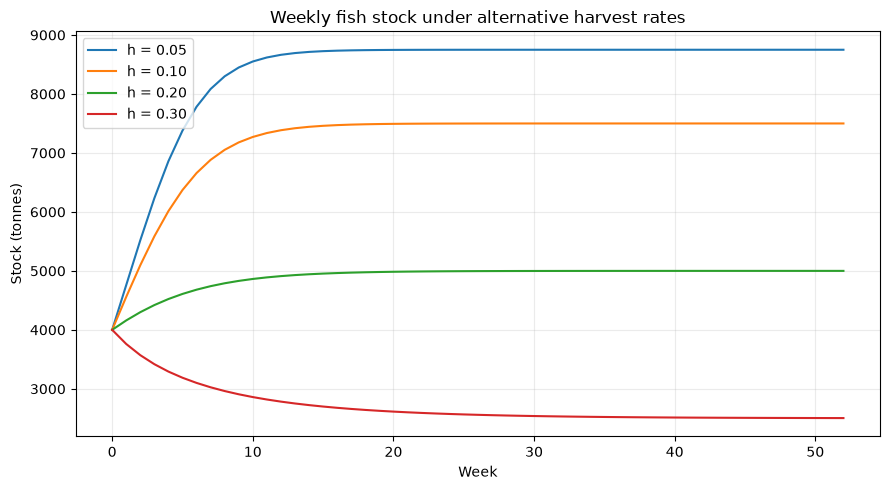

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for harvest_rate, result in scenario_results.items():
    ax.plot(
        np.arange(WEEKS + 1),
        result["stock"].stock_tonnes,
        label=f"h = {harvest_rate:.2f}",
    )
ax.set(title="Weekly fish stock under alternative harvest rates", xlabel="Week", ylabel="Stock (tonnes)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

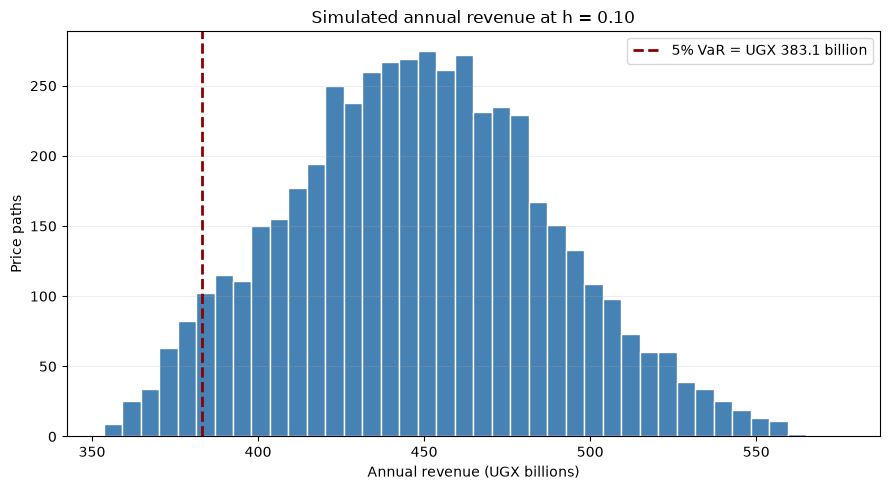

In [4]:
annual_revenue_billions = scenario_results[0.10]["revenues"] / 1e9
var_5_billions = var_5 / 1e9
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(annual_revenue_billions, bins=40, color="steelblue", edgecolor="white")
ax.axvline(var_5_billions, color="darkred", linestyle="--", linewidth=2, label=f"5% VaR = UGX {var_5_billions:.1f} billion")
ax.set(title="Simulated annual revenue at h = 0.10", xlabel="Annual revenue (UGX billions)", ylabel="Price paths")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Compare with maximum sustainable yield (MSY)

For the logistic model, the maximum weekly biological surplus occurs at `N = K/2`, so `MSY = rK/4 = 1,000 tonnes per week`. The corresponding annualized reference is 52,000 tonnes/year if that weekly surplus could be maintained all year. Compare each scenario's 52-week catch with that annualized figure; this is a simplified equilibrium benchmark, not a guarantee of sustainable yield under changing environmental conditions.

In [5]:
weekly_msy = fishery.growth_rate * fishery.carrying_capacity_tonnes / 4
annualized_msy = weekly_msy * WEEKS
print(f"Theoretical MSY: {weekly_msy:,.0f} tonnes/week ({annualized_msy:,.0f} tonnes/year annualized)")
print("h    simulated 52-week catch (tonnes)  % of annualized MSY")
for harvest_rate, result in scenario_results.items():
    total_catch = float(np.sum(result["stock"].catch_tonnes))
    print(f"{harvest_rate:.2f}  {total_catch:>30,.1f}  {total_catch / annualized_msy:>17.1%}")

Theoretical MSY: 1,000 tonnes/week (52,000 tonnes/year annualized)
h    simulated 52-week catch (tonnes)  % of annualized MSY
0.05                        21,714.6              41.8%
0.10                        37,362.5              71.9%
0.20                        50,871.7              97.8%
0.30                        42,461.0              81.7%


## Extension: eight-week closed season over five years

At `h = 0.10`, compare continuous weekly harvesting with a closure during the first eight weeks of each 52-week year. Both cases use the same seeded 260-week price path, so the revenue difference is caused by their catch schedules rather than different price draws. This is a five-year scenario comparison, not a calibrated forecast.

In [6]:
YEARS = 5
long_run_weeks = YEARS * fishery.weeks_per_year
long_run_prices = PriceModel(seed=SEED).simulate_paths(long_run_weeks)[0]
open_result = fishery.simulate(long_run_weeks, harvest_rate=0.10)
closed_result = fishery.simulate(
    long_run_weeks, harvest_rate=0.10, closed_season_weeks=8
)
open_weekly_revenue = open_result.catch_tonnes * 1_000 * long_run_prices
closed_weekly_revenue = closed_result.catch_tonnes * 1_000 * long_run_prices
open_annual = open_weekly_revenue.reshape(YEARS, -1).sum(axis=1)
closed_annual = closed_weekly_revenue.reshape(YEARS, -1).sum(axis=1)
revenue_change_pct = (closed_annual.sum() / open_annual.sum() - 1) * 100

print("Year  Open season revenue (UGX)  8-week closure revenue (UGX)")
for year, (open_revenue, closed_revenue) in enumerate(zip(open_annual, closed_annual), start=1):
    print(f"{year:>4}  {open_revenue:>24,.0f}  {closed_revenue:>29,.0f}")
print(f"Five-year open-season revenue: UGX {open_annual.sum():,.0f}")
print(f"Five-year closed-season revenue: UGX {closed_annual.sum():,.0f}")
print(f"Revenue change with closure: {revenue_change_pct:+.2f}%")
print(f"Final stock with open season: {open_result.final_stock_tonnes:,.1f} tonnes")
print(f"Final stock with closure: {closed_result.final_stock_tonnes:,.1f} tonnes")

Year  Open season revenue (UGX)  8-week closure revenue (UGX)
   1           454,319,631,969                409,966,836,638
   2           477,570,907,459                409,190,847,460
   3           395,717,958,354                339,344,861,649
   4           392,144,968,094                341,222,476,394
   5           386,564,987,724                334,796,365,552
Five-year open-season revenue: UGX 2,106,318,453,600
Five-year closed-season revenue: UGX 1,834,521,387,692
Revenue change with closure: -12.90%
Final stock with open season: 7,500.0 tonnes
Final stock with closure: 7,500.0 tonnes
